# 8 · Sector business models and working capital worldwide
Working capital is set first by **how a business gets paid**. Hotels, airlines' ticket sales, telecoms and subscriptions are paid in advance. Software and professional services invoice and wait. Grocers are paid at the till and funded by their suppliers. Manufacturers carry months of inventory. This notebook measures those models for all 52,792 companies in 123 countries:

1. 20 GICS industry groups × 8 regions: cycle, inventory, share of firms with **no inventory**, share with a **negative cycle** (customers or suppliers fund operations).
2. A **shift-share decomposition**: how much of each country's gap to the US comes from its *sector mix* and how much from *within-sector* behaviour.
3. Trends: are advance-funded (negative-cycle) businesses becoming more common?
4. Within each industry, are negative-cycle firms more profitable?

In [1]:
import sys, os, pathlib, warnings
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd().parent; sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 2); pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG, DATA = ROOT / "images", ROOT / "data"
from firmpanel import aggregate, regress
# licensed firm-level panel built by scripts/build_panel.py; it is never part of the repository
PANEL = pathlib.Path(os.environ.get("FIRMPANEL_DATA", ROOT / "private" / "panel.parquet"))
p = pd.read_parquet(PANEL)
REG_ORDER = ["North America", "Western Europe", "Japan", "Other developed Asia-Pacific", "China", "India", "OIC members", "Other emerging"]
from matplotlib.ticker import MaxNLocator
def int_years(*axes):
    for a in axes: a.xaxis.set_major_locator(MaxNLocator(integer=True)); a.set_xlabel("")
print(f"{len(p):,} firm-years, {p.gvkey.nunique():,} non-financial firms, {p['loc'].nunique()} countries, {p.fyear.min()}-{p.fyear.max()}")
IG = {"1010": "Energy", "1510": "Materials", "2010": "Capital goods", "2020": "Commercial & professional services", "2030": "Transportation",
      "2510": "Autos & components", "2520": "Consumer durables & apparel", "2530": "Consumer services", "2540": "Media & entertainment",
      "2550": "Retail", "3010": "Food & staples retail", "3020": "Food, beverage & tobacco", "3030": "Household & personal products",
      "3510": "Health care equipment & services", "3520": "Pharma & biotech", "4510": "Software & IT services", "4520": "Technology hardware",
      "4530": "Semiconductors", "5010": "Telecom services", "5020": "Media & entertainment", "6010": "Real estate"}
MODEL = {"Consumer services": "Paid in advance", "Telecom services": "Paid in advance", "Media & entertainment": "Paid in advance",
         "Software & IT services": "Asset-light, invoiced", "Commercial & professional services": "Asset-light, invoiced", "Transportation": "Asset-light, invoiced",
         "Retail": "Paid at the till", "Food & staples retail": "Paid at the till",
         "Energy": "Resources", "Materials": "Resources",
         "Capital goods": "Goods producers", "Autos & components": "Goods producers", "Consumer durables & apparel": "Goods producers",
         "Food, beverage & tobacco": "Goods producers", "Household & personal products": "Goods producers", "Technology hardware": "Goods producers",
         "Semiconductors": "Goods producers", "Health care equipment & services": "Health care", "Pharma & biotech": "Health care", "Real estate": "Real estate"}
p["industry"] = p["industry_group"].map(IG); p["model"] = p["industry"].map(MODEL)
p["no_inventory"] = (p["dio"] < 3.65).astype(float).where(p["dio"].notna())        # inventory below 1% of a year's cost of sales; firms that report inventory
p["negative_cycle"] = (p["ccc"] < 0).astype(float).where(p["ccc"].notna())
s = p[p.industry.notna()].copy()
print(f"{s.industry.nunique()} industry groups; {s.industry.notna().mean():.1%} of firm-years classified")

607,799 firm-years, 52,792 non-financial firms, 123 countries, 2000-2020


20 industry groups; 100.0% of firm-years classified


## 1. Business models around the world

In [2]:
tab = s.groupby("industry").agg(firms=("gvkey", "nunique"), cycle=("ccc", "median"), receivable=("dso", "median"), inventory=("dio", "median"),
                                payable=("dpo", "median"), no_inventory=("no_inventory", "mean"), negative=("negative_cycle", "mean"), roa=("roa", "median"))
tab[["no_inventory", "negative", "roa"]] *= 100
tab.insert(0, "model", tab.index.map(MODEL)); tab = tab.sort_values("cycle")
tab.columns = ["business model", "firms", "cycle (days)", "receivable days", "inventory days", "payable days", "% no inventory", "% negative cycle", "ROA %"]
tab.round(1).to_csv(DATA / "industry_working_capital_world.csv"); tab.round(1)

,business model,firms,cycle (days),receivable days,inventory days,payable days,% no inventory,% negative cycle,ROA %
industry,,,,,,,,,
Telecom services,Paid in advance,907,-2.7,61.2,10.7,82.5,32.8,51.8,5.4
Consumer services,Paid in advance,2355,6.7,28.7,10.4,37.2,28.9,41.2,4.6
Food & staples retail,Paid at the till,649,9.5,21.1,35.6,47.1,4.5,37.5,5.3
Transportation,"Asset-light, invoiced",1564,23.6,52.3,7.3,38.7,38.5,24.0,4.9
Energy,Resources,3034,27.2,68.6,16.8,65.1,33.5,33.9,3.5
Media & entertainment,Paid in advance,2385,36.1,76.8,4.8,57.9,47.6,28.9,4.2
Software & IT services,"Asset-light, invoiced",4505,49.1,86.8,1.1,49.7,56.4,23.1,3.4
Commercial & professional services,"Asset-light, invoiced",2091,53.5,72.3,11.6,40.8,39.3,13.2,5.9
Retail,Paid at the till,2369,57.4,25.9,73.2,48.9,7.9,17.3,5.2


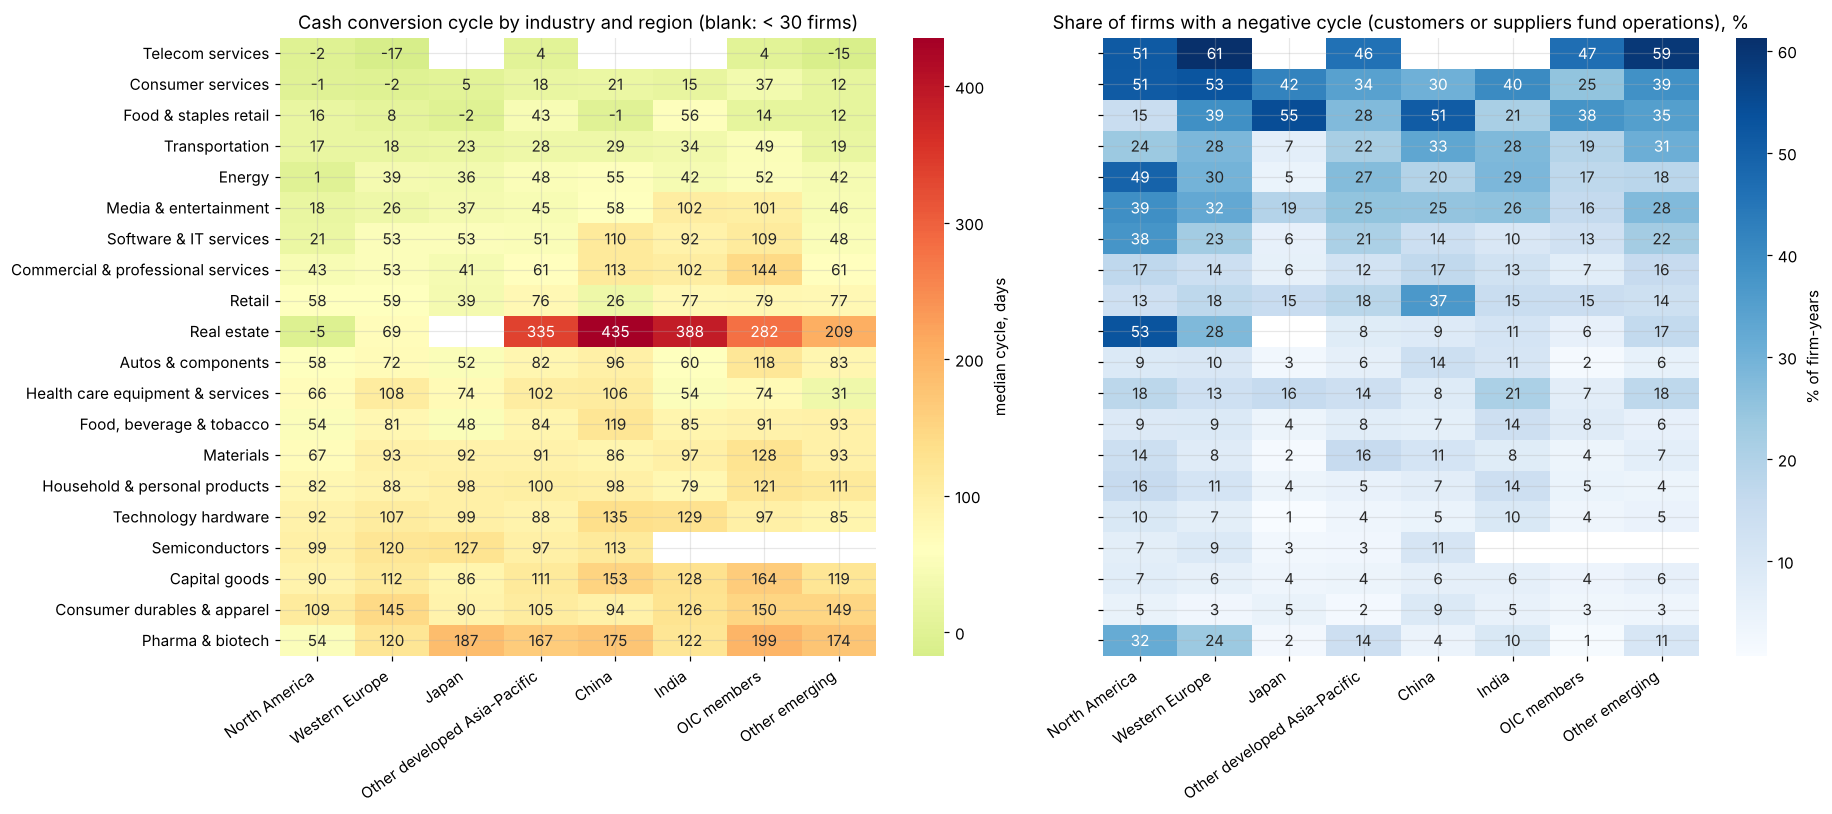

In [3]:
hm = s.groupby(["industry", "region"]).agg(c=("ccc", "median"), n=("gvkey", "nunique"))
c = hm["c"].where(hm["n"] >= 30).unstack()[REG_ORDER].reindex(tab.index)
ng = (100 * s.groupby(["industry", "region"]).negative_cycle.mean()).where(hm["n"] >= 30).unstack()[REG_ORDER].reindex(tab.index)
fig, ax = plt.subplots(1, 2, figsize=(17, 7.5))
sns.heatmap(c, annot=True, fmt=".0f", cmap="RdYlGn_r", center=60, ax=ax[0], cbar_kws={"label": "median cycle, days"})
ax[0].set_title("Cash conversion cycle by industry and region (blank: < 30 firms)")
sns.heatmap(ng, annot=True, fmt=".0f", cmap="Blues", ax=ax[1], cbar_kws={"label": "% of firm-years"})
ax[1].set_title("Share of firms with a negative cycle (customers or suppliers fund operations), %")
for a in ax: a.set_xlabel(""); a.set_ylabel(""); a.set_xticklabels(a.get_xticklabels(), rotation=35, ha="right")
ax[1].set_yticklabels([])
plt.tight_layout(); plt.savefig(IMG / "industry_region_heatmaps.png", bbox_inches="tight"); plt.show()
c.round(0).to_csv(DATA / "industry_region_cycle.csv")

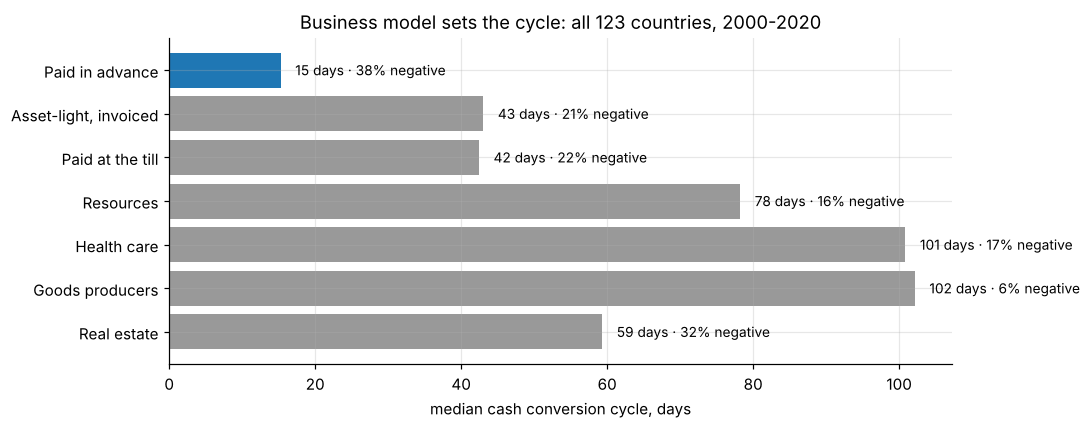

,firms,cycle,inventory,no_inventory,negative
model,,,,,
Paid in advance,5647,15.3,8.5,37.3,37.7
"Asset-light, invoiced",8160,43.0,4.8,47.6,20.7
Paid at the till,3018,42.4,59.8,7.1,22.2
Resources,9769,78.2,62.6,14.5,16.0
Health care,5364,100.8,85.5,21.9,17.1
Goods producers,19742,102.1,82.9,4.1,5.8
Real estate,726,59.3,1.7,51.4,31.8


In [4]:
mdl = s.groupby("model").agg(firms=("gvkey", "nunique"), cycle=("ccc", "median"), inventory=("dio", "median"),
                             no_inventory=("no_inventory", "mean"), negative=("negative_cycle", "mean"))
mdl[["no_inventory", "negative"]] *= 100
order = ["Paid in advance", "Asset-light, invoiced", "Paid at the till", "Resources", "Health care", "Goods producers", "Real estate"]
mdl = mdl.reindex(order)
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(mdl.index, mdl["cycle"], color=["C0" if m == "Paid in advance" else "0.6" for m in mdl.index])
for i, (v, ng_) in enumerate(zip(mdl["cycle"], mdl["negative"])): ax.text(max(v, 0) + 2, i, f"{v:.0f} days · {ng_:.0f}% negative", va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlabel("median cash conversion cycle, days"); ax.set_title("Business model sets the cycle: all 123 countries, 2000-2020")
plt.tight_layout(); plt.savefig(IMG / "business_models.png", bbox_inches="tight"); plt.show()
mdl.round(1)

## 2. Is a country's long cycle about *what* its firms do, or *how* they do it?
Shift-share decomposition against the US. For country *c*, with industry weights *w* (share of firm-years) and industry median cycles *m*:

* **mix effect** = Σ (w_c − w_US) · m_US: the gap the country would have if its firms behaved like US firms in each industry, given its industry mix;
* **within effect** = Σ w_c · (m_c − m_US): the gap from longer cycles inside the same industries.

Industries with fewer than 10 firm-years in a country use the US median (zero within effect).

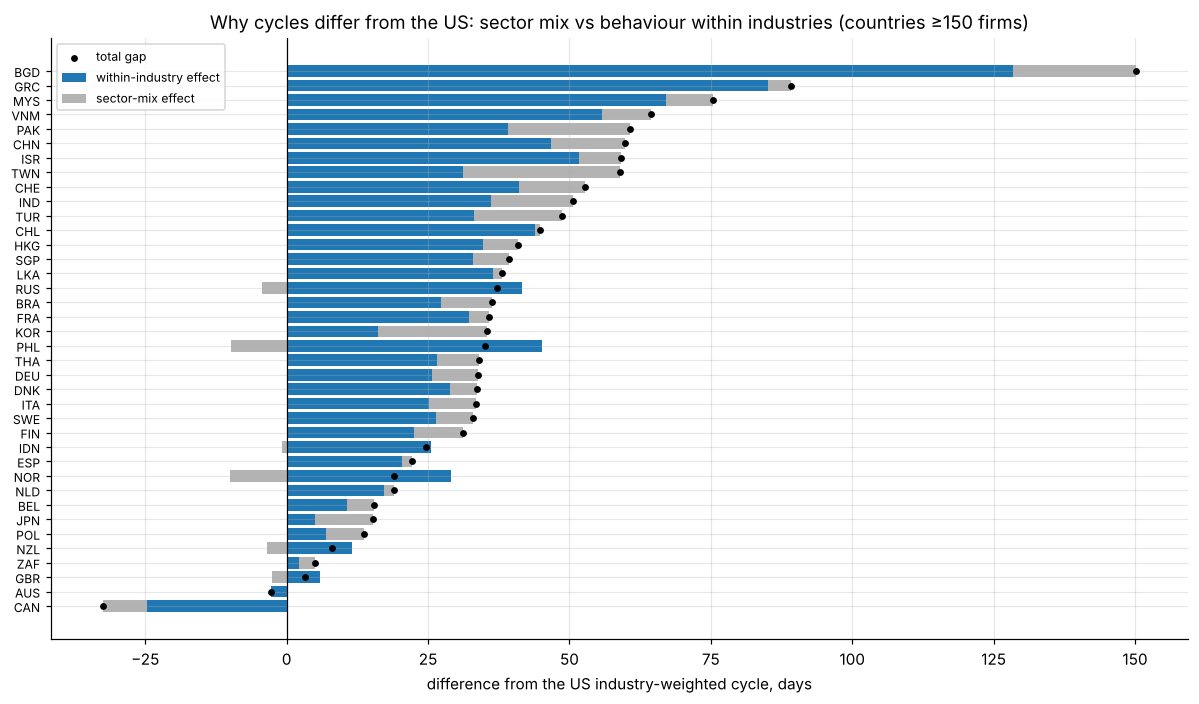

share of the total |gap| explained by within-industry behaviour (median across countries): 0.78


,region,firms,gap to US (sum),mix effect,within-industry effect
country,,,,,
CHL,Other emerging,151,44.7,0.9,43.9
TUR,OIC members,324,48.7,15.5,33.2
IND,India,3654,50.7,14.6,36.1
CHE,Western Europe,288,52.7,11.6,41.1
TWN,Other developed Asia-Pacific,2186,58.9,27.7,31.2
ISR,Other developed Asia-Pacific,497,59.1,7.4,51.7
CHN,China,4695,59.8,13.1,46.7
PAK,OIC members,334,60.7,21.6,39.2
VNM,Other emerging,483,64.5,8.7,55.8


In [5]:
us = s[s["loc"] == "USA"]; m_us = us.groupby("industry").ccc.median(); w_us = us.industry.value_counts(normalize=True)
rows = []
for loc, d in s.groupby("loc"):
    if d.gvkey.nunique() < 150 or loc == "USA": continue
    w_c = d.industry.value_counts(normalize=True); cnt = d.industry.value_counts()
    m_c = d.groupby("industry").ccc.median().where(cnt >= 10).reindex(m_us.index).fillna(m_us)
    w_c = w_c.reindex(m_us.index, fill_value=0); w_u = w_us.reindex(m_us.index, fill_value=0)
    mix = ((w_c - w_u) * m_us).sum(); within = (w_c * (m_c - m_us)).sum()
    rows.append({"country": loc, "region": d.region.iloc[0], "firms": d.gvkey.nunique(), "gap to US (sum)": mix + within, "mix effect": mix, "within-industry effect": within})
ss = pd.DataFrame(rows).set_index("country").sort_values("gap to US (sum)")
ss.round(1).to_csv(DATA / "shift_share_vs_us.csv")
fig, ax = plt.subplots(figsize=(11, 6.5))
yy = np.arange(len(ss)); ax.barh(yy, ss["within-industry effect"], color="C0", label="within-industry effect")
ax.barh(yy, ss["mix effect"], left=np.where((ss["mix effect"] > 0) == (ss["within-industry effect"] > 0), ss["within-industry effect"], 0), color="0.7", label="sector-mix effect")
ax.scatter(ss["gap to US (sum)"], yy, color="k", s=12, zorder=3, label="total gap")
ax.set_yticks(yy, ss.index, fontsize=8); ax.axvline(0, color="k", lw=0.8); ax.legend(fontsize=8)
ax.set_xlabel("difference from the US industry-weighted cycle, days"); ax.set_title("Why cycles differ from the US: sector mix vs behaviour within industries (countries ≥150 firms)")
plt.tight_layout(); plt.savefig(IMG / "shift_share_vs_us.png", bbox_inches="tight"); plt.show()
print("share of the total |gap| explained by within-industry behaviour (median across countries):",
      round(float((ss["within-industry effect"].abs() / (ss["within-industry effect"].abs() + ss["mix effect"].abs())).median()), 2))
ss.round(1).tail(12)

## 3. Are advance-funded businesses spreading?

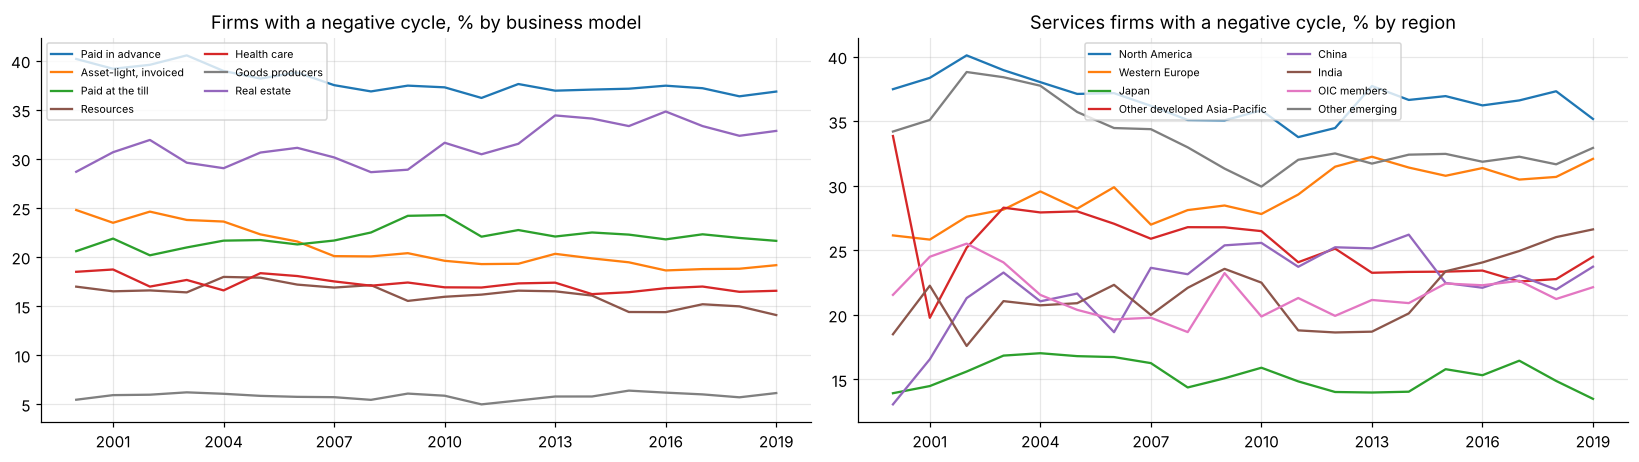

,2000,2019
model,,
Paid in advance,40.2,36.9
"Asset-light, invoiced",24.8,19.2
Paid at the till,20.6,21.6
Resources,17.0,14.1
Health care,18.5,16.5
Goods producers,5.4,6.1
Real estate,28.7,32.8


In [6]:
ny = (100 * s[s.fyear <= 2019].groupby(["fyear", "model"]).negative_cycle.mean()).unstack()[order]
ni = (100 * s[(s.fyear <= 2019) & s.model.isin(["Paid in advance", "Asset-light, invoiced"])].groupby(["fyear", "region"]).negative_cycle.mean()).unstack()[REG_ORDER]
fig, ax = plt.subplots(1, 2, figsize=(15, 4.3))
for m_, c_ in zip(order, ["C0", "C1", "C2", "C5", "C3", "0.5", "C4"]): ax[0].plot(ny.index, ny[m_], color=c_, label=m_)
ax[0].set_title("Firms with a negative cycle, % by business model"); ax[0].legend(fontsize=7, ncol=2)
ni.plot(ax=ax[1]); ax[1].set_title("Services firms with a negative cycle, % by region"); ax[1].legend(fontsize=7, ncol=2)
int_years(*ax); plt.tight_layout(); plt.savefig(IMG / "negative_cycle_trends.png", bbox_inches="tight"); plt.show()
pd.DataFrame({"2000": ny.loc[2000], "2019": ny.loc[2019]}).round(1)

## 4. Within an industry, do negative-cycle firms earn more?
Firm-year comparison within the same industry, region and year: the median operating ROA of firms with a negative cycle minus that of the other firms in the same cell (cells with at least 20 firms on each side).

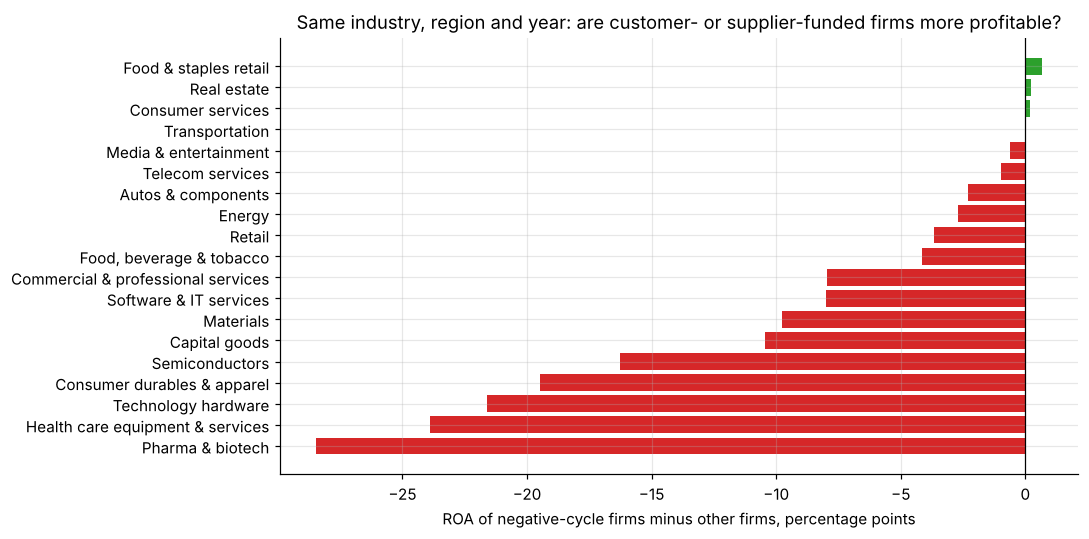

weighted average gap by region (pts): {'North America': -23.4, 'Western Europe': -5.2, 'Japan': 0.2, 'Other developed Asia-Pacific': -6.9, 'China': -0.8, 'India': -5.5, 'OIC members': -3.2, 'Other emerging': -2.4}


industry
Pharma & biotech                     -28.5
Health care equipment & services     -23.9
Technology hardware                  -21.6
Consumer durables & apparel          -19.5
Semiconductors                       -16.3
Capital goods                        -10.4
Materials                             -9.8
Software & IT services                -8.0
Commercial & professional services    -8.0
Food, beverage & tobacco              -4.2
Retail                                -3.7
Energy                                -2.7
Autos & components                    -2.3
Telecom services                      -1.0
Media & entertainment                 -0.6
Transportation                         0.0
Consumer services                      0.2
Real estate                            0.2
Food & staples retail                  0.7
Name: ROA gap, pts, dtype: float64

In [7]:
cell = s.dropna(subset=["negative_cycle", "roa"]).groupby(["industry", "region", "fyear"])
def diff(d):
    a, b = d[d.negative_cycle == 1].roa, d[d.negative_cycle == 0].roa
    return pd.Series({"gap": 100 * (a.median() - b.median()), "n": len(d)}) if len(a) >= 20 and len(b) >= 20 else pd.Series({"gap": np.nan, "n": len(d)})
dd = cell.apply(diff).dropna()
by_ind = dd.groupby("industry").apply(lambda x: np.average(x.gap, weights=x.n)).sort_values()
by_reg = dd.groupby("region").apply(lambda x: np.average(x.gap, weights=x.n)).reindex(REG_ORDER)
fig, ax = plt.subplots(figsize=(10, 5)); ax.barh(by_ind.index, by_ind.values, color=["C2" if v > 0 else "C3" for v in by_ind.values]); ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("ROA of negative-cycle firms minus other firms, percentage points"); ax.set_title("Same industry, region and year: are customer- or supplier-funded firms more profitable?")
plt.tight_layout(); plt.savefig(IMG / "negative_cycle_profitability.png", bbox_inches="tight"); plt.show()
print("weighted average gap by region (pts):", by_reg.round(1).to_dict())
by_ind.round(1).rename("ROA gap, pts")

## Findings
* **The business model sets working capital.** Across all 123 countries, "paid in advance" businesses (telecoms, consumer services such as hotels, restaurants, education and leisure, and media) have a median cycle of 15 days, and 38% of them run a negative cycle. Asset-light invoicing businesses (software, professional services, transport) and retailers sit near 43 days. Goods producers need 102 days, and only 6% of them run negative.
* **Inventory separates services from goods.** 56% of software and IT firms, 48% of media firms and 39% of commercial-services firms report essentially no inventory (below 1% of a year's cost of sales), against 1-3% of manufacturers. Their cycle is driven by collection terms alone.
* **The same industry looks very different by region.** Telecoms run negative cycles in North America (-2 days), Western Europe (-17) and emerging markets (-15). Software firms take 21 days in North America but 110 in China, 109 in OIC countries and 92 in India, mainly because of slower collection. Real estate is the outlier: Asian and emerging-market developers carry unsold property as inventory (cycles of 280-435 days).
* **Country gaps are mostly behaviour, not sector mix.** In a shift-share decomposition against the US, within-industry differences explain a median 78% of each country's gap. Bangladesh (+150 days), Greece (+89), Malaysia (+75) and Vietnam (+65) are long-cycle countries in nearly every industry. Only Taiwan has a large mix effect (+28 days, from its electronics-hardware weighting). Canada and Australia run shorter cycles than the US.
* **Advance-funded models are not spreading.** The share of negative-cycle firms has been stable or slightly lower since 2000 in every business model: 40% → 37% for paid-in-advance and 25% → 19% for asset-light services. Services firms in Western Europe and India moved up, and North America down.
* **A negative cycle is good news only in services.** Within the same industry, region and year, negative-cycle firms earn about the same ROA as their peers in consumer services, telecoms, media, transport and food retail. In pharma (-28 points), health-care equipment (-24), hardware (-22) and consumer durables (-20) they earn far less. There a negative cycle usually means a loss-making company with little revenue that is stretching its suppliers, not a business paid in advance. For credit analysis, a negative cycle in a manufacturer or a biotech is a warning sign; in a subscription or ticketing business it is a strength.